<a href="https://colab.research.google.com/github/chaitreshkondisetty/my-first-repo/blob/main/SEC190_Endterm_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SEC 190 Endterm Project

## Relationship Between Car Weight and Fuel Efficiency

**Dataset:** Auto MPG Dataset

**Source:** UCI Machine Learning Repository

**Research Question:** How does car weight affect fuel efficiency?

## 1. Dataset Description

The Auto MPG dataset is obtained from the UCI Machine Learning Repository. It contains information about automobiles and their fuel efficiency.

The dataset includes variables such as MPG, cylinders, displacement, horsepower, weight, acceleration, model year, origin, and car name.

For this project, car weight is selected as the predictor variable (X), and MPG is selected as the response variable (Y).

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [10]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "car_name"
]

df = pd.read_csv(url, sep=r"\s+", names=columns, na_values="?")

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [12]:
df.shape

(398, 9)

The dataset contains 398 observations (cars) and 9 variables (columns). It satisfies the assignment requirement of at least 20 rows and two numerical variables.

In [13]:
X = df[["weight"]]
y = df["mpg"]

The predictor variable (X) is car weight, measured in pounds. The response variable (Y) is fuel efficiency, measured in miles per gallon (MPG).

These variables were selected because the project investigates whether car weight is related to fuel efficiency.

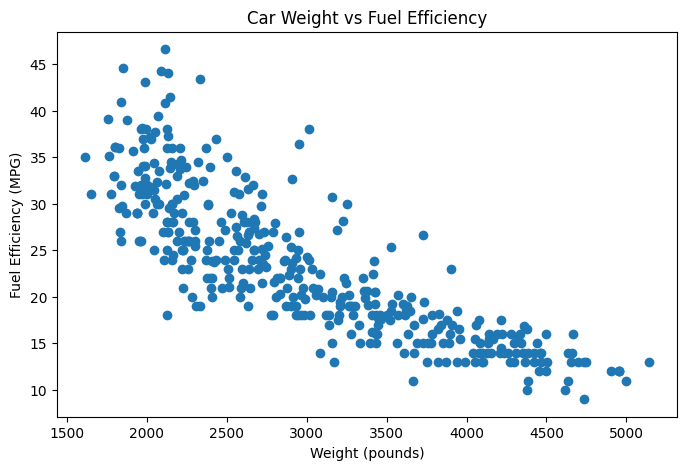

In [15]:

plt.figure(figsize=(8,5))

plt.scatter(df["weight"], df["mpg"])

plt.title("Car Weight vs Fuel Efficiency")
plt.xlabel("Weight (pounds)")
plt.ylabel("Fuel Efficiency (MPG)")

plt.show()


In [16]:
linear_model = LinearRegression()

linear_model.fit(X, y)

linear_predictions = linear_model.predict(X)

linear_r2 = r2_score(y, linear_predictions)

print("Linear R²:", linear_r2)
print("Slope:", linear_model.coef_[0])
print("Intercept:", linear_model.intercept_)

Linear R²: 0.6917929800341573
Slope: -0.007676610063926465
Intercept: 46.31736442026563


### Interpretation of Linear Regression

The linear regression model obtained an R² value of 0.6918, indicating that approximately 69.18% of the variation in fuel efficiency is explained by car weight.

The negative slope indicates that fuel efficiency decreases as car weight increases. Therefore, a negative relationship exists between car weight and MPG.

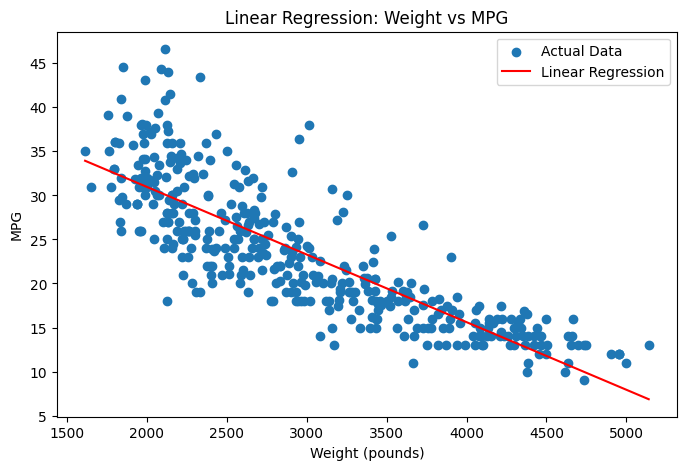

In [17]:

order = np.argsort(df["weight"])

plt.figure(figsize=(8,5))

plt.scatter(df["weight"], df["mpg"], label="Actual Data")

plt.plot(
    df["weight"].iloc[order],
    linear_predictions[order],
    color="red",
    label="Linear Regression"
)

plt.title("Linear Regression: Weight vs MPG")
plt.xlabel("Weight (pounds)")
plt.ylabel("MPG")
plt.legend()

plt.show()


### Interpretation of Linear Regression Graph

The linear regression line shows a negative relationship between car weight and fuel efficiency. As car weight increases, MPG decreases. The regression line represents the predicted fuel efficiency for different car weights.

## 10. R² Interpretation

The linear regression model obtained an R² value of 0.6918. This indicates that approximately 69.18% of the variation in MPG is explained by car weight. The remaining variation is influenced by other factors and random variation.

## 11. Quadratic Regression

Quadratic regression is used to identify a nonlinear relationship between car weight and fuel efficiency. It helps determine whether a curved model fits the data better than a linear model.

In [18]:

from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

quadratic_model = LinearRegression()

quadratic_model.fit(X_poly, y)

quadratic_predictions = quadratic_model.predict(X_poly)

quadratic_r2 = r2_score(y, quadratic_predictions)

print("Quadratic R²:", quadratic_r2)


Quadratic R²: 0.714788125827216


## 12. Comparison of Linear and Quadratic Regression

Both linear and quadratic regression models are plotted on the same scatter plot to compare their fitting performance and identify whether the relationship between car weight and MPG is linear or nonlinear.

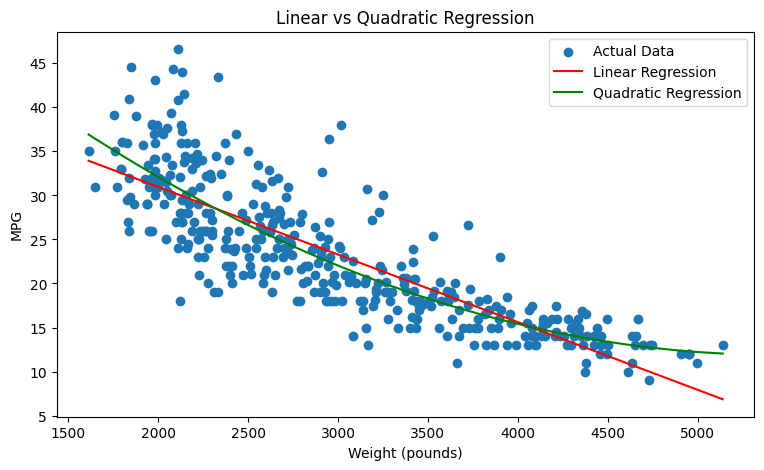

In [19]:

plt.figure(figsize=(9,5))

plt.scatter(df["weight"], df["mpg"], label="Actual Data")

plt.plot(
    df["weight"].iloc[order],
    linear_predictions[order],
    color="red",
    label="Linear Regression"
)

plt.plot(
    df["weight"].iloc[order],
    quadratic_predictions[order],
    color="green",
    label="Quadratic Regression"
)

plt.title("Linear vs Quadratic Regression")
plt.xlabel("Weight (pounds)")
plt.ylabel("MPG")
plt.legend()

plt.show()


## 13. Model Comparison

The linear regression model obtained an R² value of 0.6918, while the quadratic regression model obtained an R² value of 0.7148.

The quadratic model has a higher R² value and explains approximately 71.48% of the variation in MPG, compared to 69.18% for the linear model.

The improvement is approximately 2.30 percentage points. Therefore, the quadratic model provides a slightly better fit to the dataset.

## 14. Conclusion and Recommendation

The analysis was performed using the Auto MPG dataset containing 398 automobile observations.

The scatter plot shows a negative relationship between car weight and fuel efficiency. As car weight increases, MPG generally decreases.

The linear regression model obtained an R² value of 0.6918, while the quadratic regression model obtained an R² value of 0.7148.

The quadratic regression model provides a slightly better fit than the linear model. Therefore, the quadratic model is preferable for describing the curvature in the relationship between car weight and MPG.

Overall, car weight is an important factor associated with automobile fuel efficiency. Lighter cars generally provide better fuel efficiency than heavier cars.